# Semana 8 — Dinámica de poblaciones: modelo de Wilson–Cowan

**Objetivo:** ver cómo una población excitatoria (E) y una inhibitoria (I) acopladas pasan de un
estado estable a una oscilación al cambiar solo la entrada externa.

## Modelo

$$\tau_E \frac{dE}{dt} = -E + F_E\big(w_{EE}E - w_{EI}I + I_E^\text{ext}\big)$$

$$\tau_I \frac{dI}{dt} = -I + F_I\big(w_{IE}E - w_{II}I + I_I^\text{ext}\big)$$

con una sigmoide desplazada para que $F(0) = 0$:

$$F(x; a, \theta) = \frac{1}{1 + e^{-a(x - \theta)}} - \frac{1}{1 + e^{a\theta}}$$

Parámetros (los del tutorial de Neuromatch W2D4, régimen oscilatorio):

| | $\tau$ | $a$ | $\theta$ |
|---|---|---|---|
| E | 1 | 1.2 | 2.8 |
| I | 2 | 1.0 | 4.0 |

$w_{EE} = 6.4$, $w_{EI} = 4.8$, $w_{IE} = 6.0$, $w_{II} = 1.2$. Tiempo en unidades de $\tau_E$.

## Nullclines

Son las curvas donde una variable no cambia. Los puntos fijos están en sus intersecciones:

- $\dot E = 0$: $\;I = \big(w_{EE}E + I_E^\text{ext} - F_E^{-1}(E)\big) / w_{EI}$
- $\dot I = 0$: $\;E = \big(F_I^{-1}(I) + w_{II}I - I_I^\text{ext}\big) / w_{IE}$

Experimento: misma conectividad, tres valores de $I_E^\text{ext}$ (0.4, 0.8, 1.5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 8
TAU_E, A_E, THETA_E = 1.0, 1.2, 2.8
TAU_I, A_I, THETA_I = 2.0, 1.0, 4.0
W_EE, W_EI, W_IE, W_II = 6.4, 4.8, 6.0, 1.2
DT = 0.01
DURATION = 100.0
EXTERNAL_E = {"Low input (0.4)": 0.4, "Medium input (0.8)": 0.8, "High input (1.5)": 1.5}


def sigmoid(x, a, theta):
    return 1.0 / (1.0 + np.exp(-a * (x - theta))) - 1.0 / (1.0 + np.exp(a * theta))


def inverse_sigmoid(y, a, theta):
    return theta - np.log(1.0 / (y + 1.0 / (1.0 + np.exp(a * theta))) - 1.0) / a


def simulate(external_e: float, external_i: float = 0.0, e0: float = 0.32, i0: float = 0.15):
    time = np.arange(0.0, DURATION + DT / 2, DT)
    rates = np.empty((time.size, 2))
    rates[0] = e0, i0
    for k in range(time.size - 1):
        e, i = rates[k]
        rates[k + 1, 0] = e + DT * (-e + sigmoid(W_EE * e - W_EI * i + external_e, A_E, THETA_E)) / TAU_E
        rates[k + 1, 1] = i + DT * (-i + sigmoid(W_IE * e - W_II * i + external_i, A_I, THETA_I)) / TAU_I
    return time, rates


def nullclines(external_e: float, external_i: float = 0.0):
    offset_e = 1.0 / (1.0 + np.exp(A_E * THETA_E))
    offset_i = 1.0 / (1.0 + np.exp(A_I * THETA_I))
    e_values = np.linspace(-offset_e + 1e-4, 1.0 - offset_e - 1e-4, 400)
    i_values = np.linspace(-offset_i + 1e-4, 1.0 - offset_i - 1e-4, 400)
    e_nullcline_i = (W_EE * e_values + external_e - inverse_sigmoid(e_values, A_E, THETA_E)) / W_EI
    i_nullcline_e = (inverse_sigmoid(i_values, A_I, THETA_I) + W_II * i_values - external_i) / W_IE
    return (e_values, e_nullcline_i), (i_nullcline_e, i_values)


runs = {label: simulate(value) for label, value in EXTERNAL_E.items()}

## Figura

Fila superior: actividad en el tiempo. Fila inferior: plano de fase $(E, I)$ con las nullclines
y la trayectoria (el último tramo, en negro, muestra el estado final: un punto o un ciclo límite).

Saved: weeks/week_08_wilson_cowan/outputs/wilson_cowan.png
Saved: weeks/week_08_wilson_cowan/outputs/wilson_cowan.npz


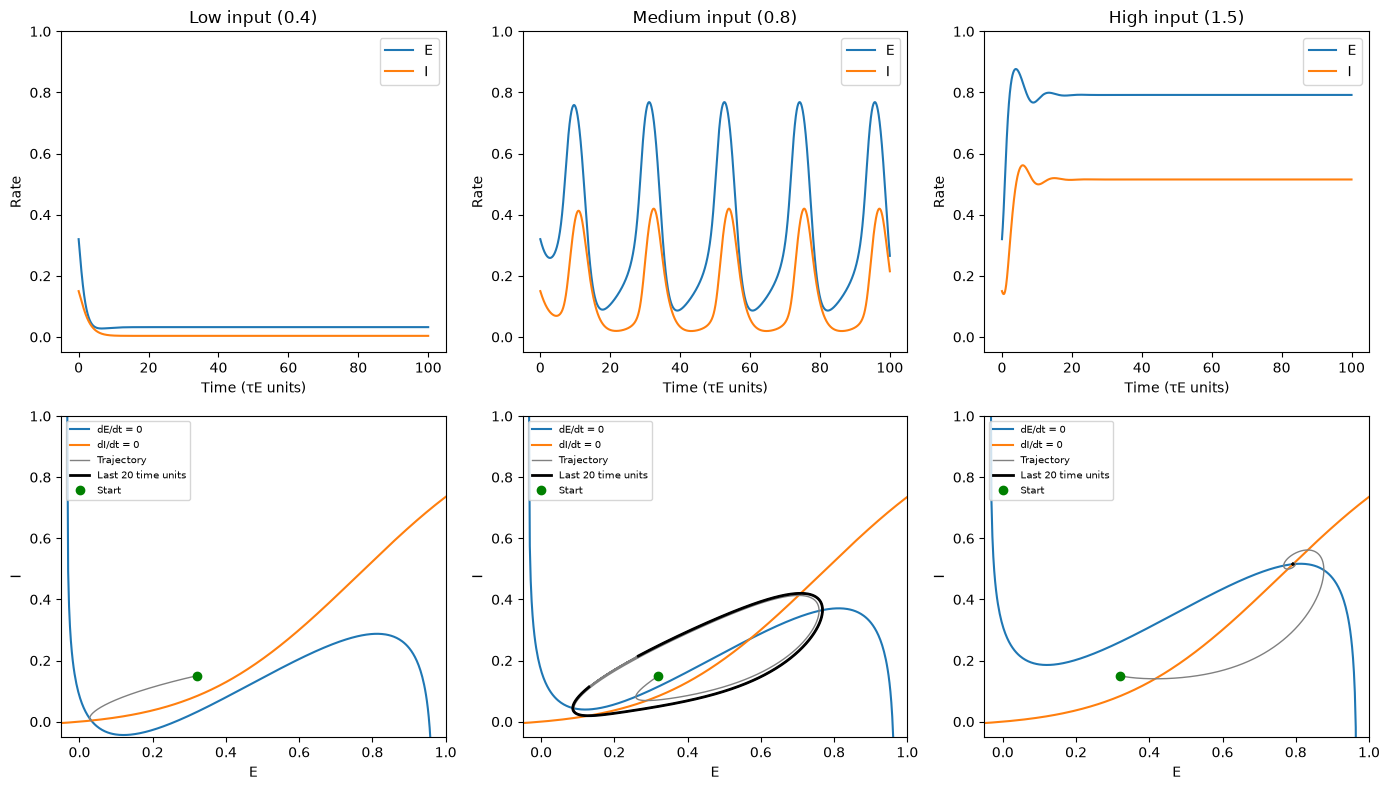

In [2]:
figure, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, (label, (time, rates)) in enumerate(runs.items()):
    top, bottom = axes[0, column], axes[1, column]
    top.plot(time, rates[:, 0], label="E")
    top.plot(time, rates[:, 1], label="I")
    top.set(xlabel="Time (τE units)", ylabel="Rate", title=label, ylim=(-0.05, 1.0))
    top.legend(loc="upper right")
    (e_line, e_line_i), (i_line_e, i_line) = nullclines(EXTERNAL_E[label])
    bottom.plot(e_line, e_line_i, color="tab:blue", label="dE/dt = 0")
    bottom.plot(i_line_e, i_line, color="tab:orange", label="dI/dt = 0")
    bottom.plot(rates[:, 0], rates[:, 1], color="grey", linewidth=1, label="Trajectory")
    tail = time > DURATION - 20.0
    bottom.plot(rates[tail, 0], rates[tail, 1], color="black", linewidth=2, label="Last 20 time units")
    bottom.plot(*rates[0], "go", label="Start")
    bottom.set(xlabel="E", ylabel="I", xlim=(-0.05, 1.0), ylim=(-0.05, 1.0))
    bottom.legend(fontsize=7, loc="upper left")
save_figure(WEEK, figure, "wilson_cowan.png")
save_data(WEEK, "wilson_cowan.npz", time=runs["Low input (0.4)"][0], external_e=np.array(list(EXTERNAL_E.values())),
          **{f"rates_input_{value:g}": rates for value, (_, rates) in zip(EXTERNAL_E.values(), runs.values())})

## Validación

- Entrada baja y alta: la actividad converge a un punto fijo (amplitud final ≈ 0) que está en
  la intersección de las nullclines ($\dot E \approx 0$ y $\dot I \approx 0$).
- Entrada media: oscilación sostenida (ciclo límite) con amplitud apreciable.
- Se estima el período de la oscilación a partir de los cruces por la media.

In [3]:
def late_amplitude(rates: np.ndarray) -> float:
    return float(np.ptp(rates[-int(20.0 / DT):, 0]))


for label in ("Low input (0.4)", "High input (1.5)"):
    _, rates = runs[label]
    e, i = rates[-1]
    external = EXTERNAL_E[label]
    assert late_amplitude(rates) < 1e-3, label
    assert abs(-e + sigmoid(W_EE * e - W_EI * i + external, A_E, THETA_E)) < 1e-4
    assert abs(-i + sigmoid(W_IE * e - W_II * i, A_I, THETA_I)) < 1e-4
    print(f"{label}: fixed point E={e:.3f}, I={i:.3f}")

time, rates = runs["Medium input (0.8)"]
assert late_amplitude(rates) > 0.3
late = time > DURATION / 2
e_late = rates[late, 0]
upward = np.flatnonzero((e_late[:-1] < e_late.mean()) & (e_late[1:] >= e_late.mean()))
period = float(np.mean(np.diff(time[late][upward])))
print(f"Medium input (0.8): limit cycle, E amplitude {late_amplitude(rates):.2f}, period ~ {period:.2f} tauE")

Low input (0.4): fixed point E=0.032, I=0.004
High input (1.5): fixed point E=0.792, I=0.515
Medium input (0.8): limit cycle, E amplitude 0.68, period ~ 21.52 tauE


## Interpretación y límites

- Con entrada media, el punto fijo de la intersección se vuelve inestable y aparece un ciclo
  límite: la excitación sube, recluta inhibición (más lenta, $\tau_I = 2\tau_E$), la inhibición
  apaga la excitación y el ciclo se repite.
- Con entrada baja o alta, el punto fijo es estable: actividad baja o actividad saturada.
- Es un modelo de tasas promedio: no hay spikes individuales ni ruido.

**Para tu entrega:** barre $I_E^\text{ext}$ entre 0 y 2 y anota en qué valores aparece y
desaparece la oscilación.